# 제공 재무·고용 자료의 실데이터 재분석

138개 기업의 원본 대조와 125개 기업의 2021→2022 탐색 실험입니다. 통화·연결 범위·실제 수집 연도·공시 시점은 제공 파일에서 확인하지 못했습니다. 여러 미래 연도 성능을 입증한 실험은 아닙니다.

실행 환경: 저장소에서 `uv sync --locked --no-editable` 후 해당 가상환경의 커널을 선택합니다.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from data_final.legacy import build_legacy_examples
from data_final.legacy_analysis import analyze_legacy

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
panel = pd.read_csv(ROOT / "data/reference/legacy_panel.csv")
audit = json.loads((ROOT / "reports/legacy/source_audit.json").read_text())

## 1. 무엇이 잘못됐는가

결측값의 양수 대체, 의미가 다른 계정의 통합, 중복 기업과 직원수 충돌을 파일 대조로 확인했습니다. 원본 값이 있는 경우에는 그 값을 보존합니다.

In [2]:
pd.DataFrame(audit["fill_audit"]).T

,filled_cells,changed_observed_cells,raw_global_median,replacement_values
2021,598,0,33087031231.0,[33087031231]
2022,536,0,33898331929.0,[33898331929]


In [3]:
pd.DataFrame(audit["unsafe_total_mappings"])

,계정과목_원본,계정과목_표준,rows
0,부채와 자본총계,자본총계,2
1,부채와자본총계,자본총계,8
2,자본과 부채총계,부채총계,1
3,자본과부채총계,부채총계,85


In [4]:
pd.read_csv(ROOT / "reports/legacy/target_audit.csv").query("label_disagrees")

,company,net_income,legacy_aggregated_net_income,legacy_target_was_missing,legacy_model_target,label_disagrees
101,코오롱티슈진,-8619693.0,3.388109e+10,False,3.388109e+10,True


## 2. 자료의 범위에 맞게 질문 바꾸기

2021년 재무 비율 4개와 직원수 1개로 2022년 적자를 분류합니다. 2022년 직원수 증가율은 예측 입력에서 제외했습니다. 통화 정보가 없어 원시 금액 크기도 비교하지 않습니다. 같은 기업 안의 비율 계산에 필요한 단위·범위 일치 가정은 남아 있습니다.

In [5]:
examples, eligibility = build_legacy_examples(panel)
display(eligibility.exclusion_reason.value_counts())
display(
    examples[
        [
            "company",
            "return_on_assets_2021",
            "net_margin_2021",
            "operating_margin_2021",
            "leverage_2021",
            "log_employees_2021",
            "loss_2022",
        ]
    ].head()
)

exclusion_reason
included                             125
fewer_than_two_financial_features      7
missing_target                         6
Name: count, dtype: int64

,company,return_on_assets_2021,net_margin_2021,operating_margin_2021,leverage_2021,log_employees_2021,loss_2022
0,CJ,NaN,0.023401,0.054570,NaN,9.114160,0
1,CJ대한통운,NaN,0.013953,0.030315,NaN,8.756525,0
2,CJ바이오사이언스,-0.165634,-4.417195,-2.316755,0.244958,6.118097,1
3,CJ제일제당,0.033229,0.033945,0.057987,0.597599,9.114160,0
4,DL이앤씨,NaN,0.083316,0.125433,NaN,8.605570,0


## 3. 평가와 모델 선택 분리

외부 5-fold를 5회 반복하고, 각 외부 학습셋의 3-fold에서 AP로 모델과 피처 구성을 선택합니다. 모든 대체·스케일링은 해당 학습 Pipeline에서만 fit합니다. 회사는 한 반복 안에서 한 번만 외부 평가를 받습니다. 반복 범위는 신뢰구간이 아닙니다.

In [6]:
OUT = ROOT / "reports/runs/real_notebook"
result = analyze_legacy(panel, OUT)
summary = pd.read_csv(OUT / "model_summary.csv")
display(
    summary[
        [
            "model",
            "n",
            "roc_auc_mean",
            "average_precision_mean",
            "accuracy_mean",
            "loss_recall_mean",
        ]
    ]
)

,model,n,roc_auc_mean,average_precision_mean,accuracy_mean,loss_recall_mean
0,boosting_employment,125,0.78748,0.573630,0.8496,0.472
1,boosting_financial,125,0.80040,0.530079,0.8544,0.520
2,class_prior,125,0.50000,0.200000,0.8000,0.000
3,logistic_employment,125,0.76152,0.580668,0.8496,0.344
4,logistic_financial,125,0.75096,0.579596,0.8464,0.320
5,nested_selection,125,0.77116,0.570751,0.8352,0.384
6,previous_loss,125,0.77500,0.481600,0.8560,0.640


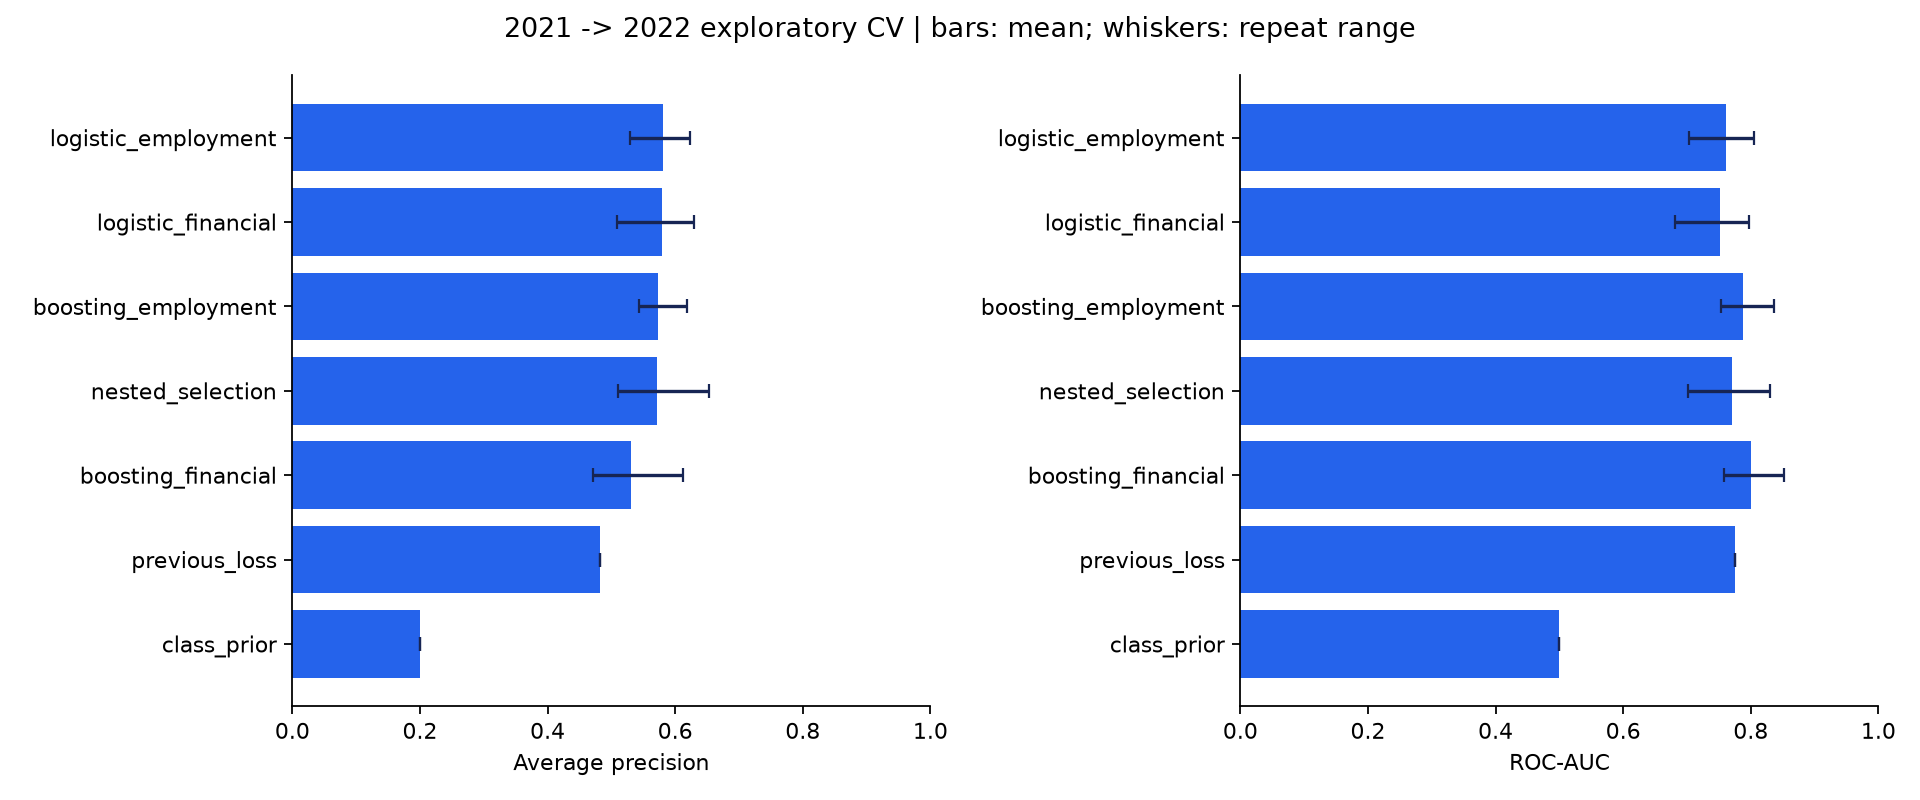

In [7]:
display(Image(filename=str(OUT / "comparison.png")))

## 4. 복잡한 모델이 필요한가

전년 손익 상태 유지 기준의 정확도와 적자 재현율이 내부 선택 절차보다 좋았습니다. AP는 선택 절차가 더 높아 지표별 판단이 달랐습니다. 기존 95.24%는 다른 문제의 결과라 이번 점수와 직접 비교하지 않습니다.

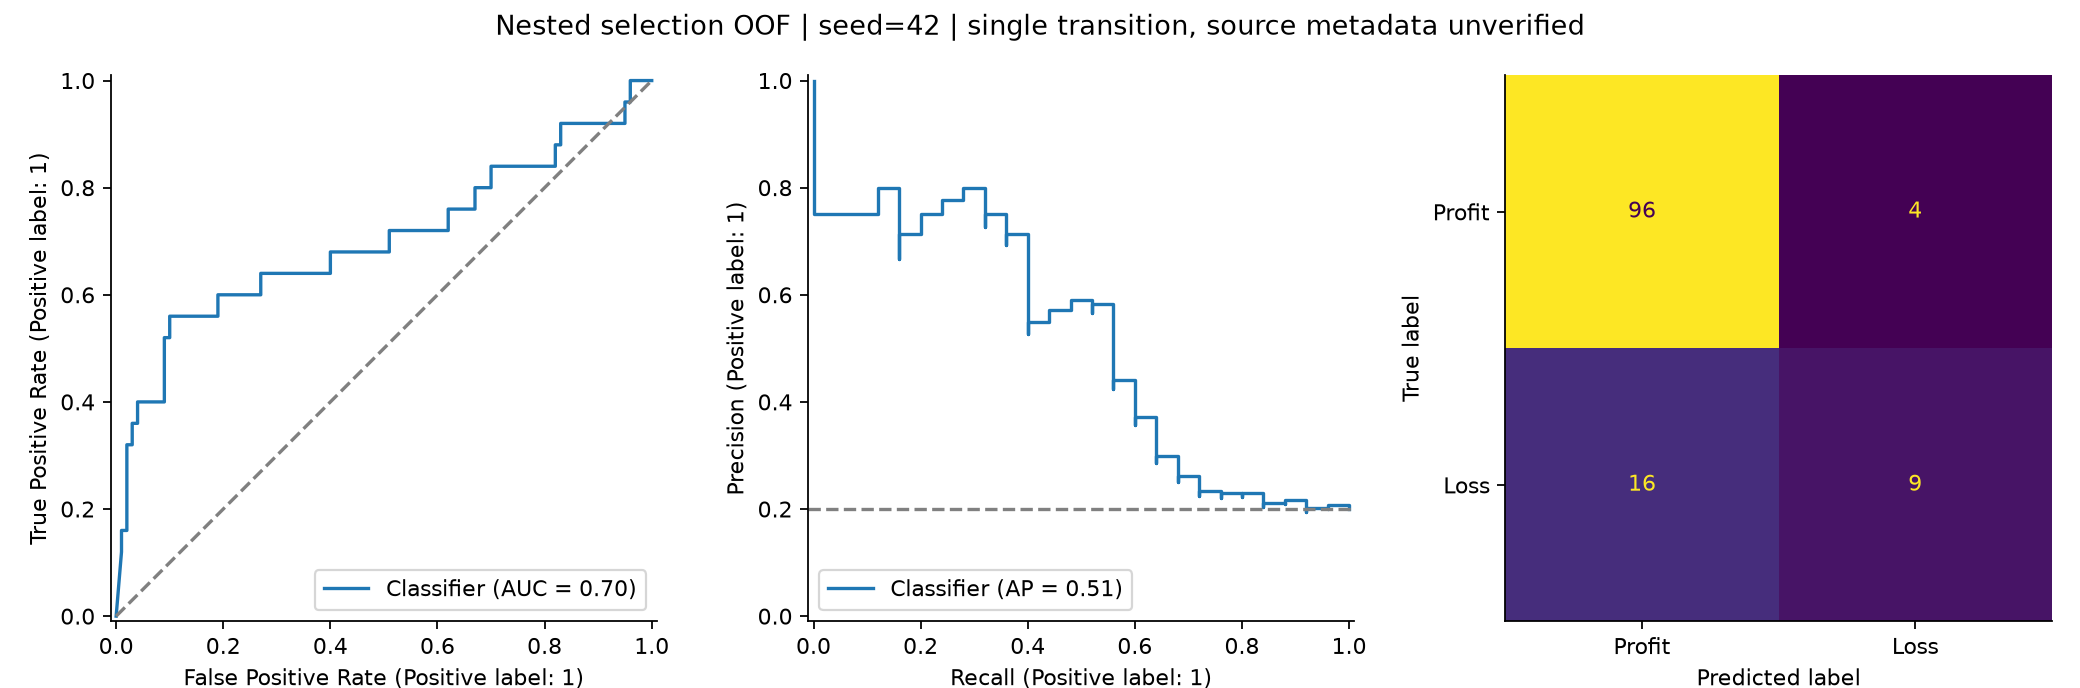

In [8]:
display(Image(filename=str(OUT / "evaluation.png")))

## 5. 직원수의 추가 가치는 안정적인가

같은 모델·같은 기업·같은 분할에서 피처만 바꿉니다. 반복 직원수 쌍 제외 분석은 사후 진단이며 그 플래그 자체는 예측 입력이 아닙니다.

In [9]:
display(pd.read_csv(OUT / "employment_ablation.csv"))
display(
    pd.read_csv(OUT / "employee_sensitivity.csv")[
        ["model", "n", "average_precision_mean", "loss_recall_mean"]
    ]
)

,seed,employment_ap_delta,employment_auc_delta
0,42,0.020010,0.0212
1,43,0.010587,0.0104
2,44,-0.007699,0.0136
3,45,-0.007156,0.0080
4,46,-0.010382,-0.0004


,model,n,average_precision_mean,loss_recall_mean
0,class_prior,110,0.199605,0.000000
1,logistic_employment,110,0.579656,0.330435
2,logistic_financial,110,0.588377,0.278261
3,previous_loss,110,0.487615,0.608696


## 6. 고용 변화와 이익 변화

직원수 변화율과 순이익 변화/2021년 자산을 비교합니다. Pearson과 Spearman을 함께 보고 p값은 탐색용으로만 읽습니다. 관측 관계로 인과 효과를 주장하지 않습니다.

,sample,n,pearson_r,pearson_p_exploratory,spearman_r,spearman_p_exploratory
0,all_complete_pairs,102,0.123153,0.217518,0.152440,0.126128
1,exclude_repeated_employee_pairs,88,0.135540,0.207989,0.172697,0.107618


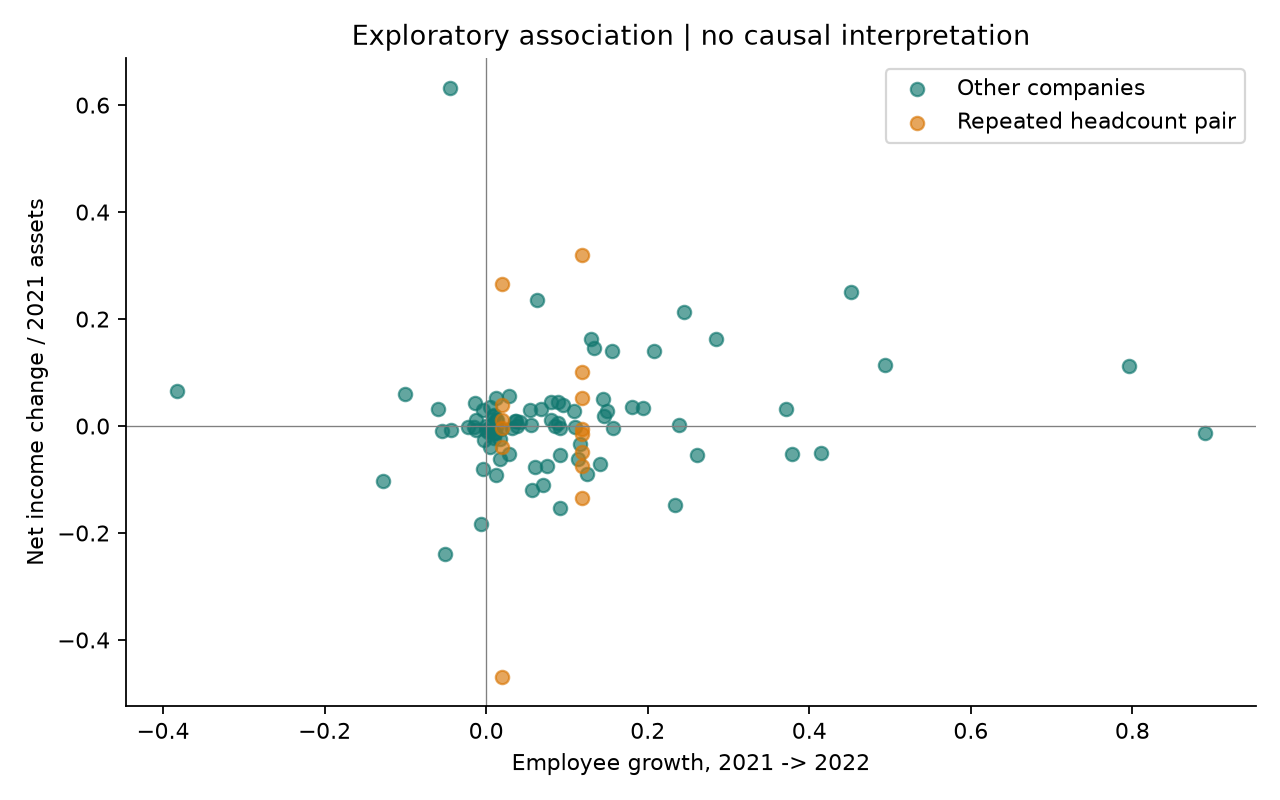

In [10]:
display(pd.DataFrame(result["associations"]["comparisons"]))
display(Image(filename=str(OUT / "association.png")))

## 7. 포트폴리오 결론

정답 생성 전 원본 대조, 계정 의미 보존, 누수 방지, 기준 모델 비교, 추가 피처의 가치 검증을 수행했습니다. 직원수의 안정적인 개선이나 복잡한 모델의 전반적인 우위는 확인하지 못했습니다. 다음 단계는 공시 원문 메타데이터 확보와 다년도 검증입니다.

[전체 사례 연구](../docs/case_study.md) · [발표·면접 문안](../docs/portfolio.md) · [평가 설계](../docs/legacy_methodology.md)